# Lab: Experiment Tracking and Model Registry with MLflow (Modified)

*Modified by Nishit Chaudhary from the course's MLflow Lab 2 (wine quality).*

The task is unchanged: predict whether a wine is **high quality** (score ≥ 7) from its chemistry. The changes are to **how experiments are tracked, compared, registered and promoted**:

| Part | What it does |
|---|---|
| **1. Tracking setup** | A named experiment with a local SQLite backend, so the model registry works reliably |
| **2. Three model families** | Random forest baseline, an XGBoost Hyperopt sweep as **nested runs**, and a **TensorFlow/Keras** network with per-epoch autologging |
| **3. Consistent metrics** | Every candidate logs the same `val_*` metrics and plots. Selection uses **validation only**; the test set is used once, at the end |
| **4. Leaderboard** | Runs compared from code with `mlflow.search_runs` filters |
| **5. Registry** | **Aliases** (`champion` / `challenger`) instead of deprecated stages, plus a **promotion gate** |
| **6. Use the champion** | Test evaluation, batch inference without Spark, and REST serving by alias |

See `README.md` for setup, the MLflow UI, serving, and the full list of changes.

## 1. Tracking setup

**Run the MLflow UI in a separate terminal**, not inside the notebook. The original's `!mlflow ui` cell never finishes and blocks the kernel. From this folder, with the virtual environment active:

```
mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db --port 5000
```

Then open http://127.0.0.1:5000.

Tracking data goes to a **SQLite database** in `mlruns/` instead of plain files, because the model registry and aliases need a database backend. Artifacts (models, plots, predictions) go to `mlruns/` as well. The repo's `.gitignore` already excludes `mlruns/`, so none of it is committed.

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import tensorflow as tf
import xgboost as xgb
from hyperopt import STATUS_OK, Trials, fmin, hp, tpe
from hyperopt.pyll import scope
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             accuracy_score, f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split

import mlflow
import mlflow.pyfunc
from mlflow.exceptions import MlflowException
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient

warnings.filterwarnings("ignore", category=UserWarning)
os.makedirs("mlruns", exist_ok=True)

TRACKING_URI = "sqlite:///mlruns/mlflow.db"
EXPERIMENT_NAME = "wine_quality_tracking"
MODEL_NAME = "wine_quality"
SEED = 42

mlflow.set_tracking_uri(TRACKING_URI)
experiment = mlflow.set_experiment(EXPERIMENT_NAME)
client = MlflowClient()

print("MLflow:", mlflow.__version__, "| TensorFlow:", tf.__version__, "| XGBoost:", xgb.__version__,
      "| scikit-learn:", sklearn.__version__)
print(f"Experiment '{EXPERIMENT_NAME}' (id {experiment.experiment_id}) tracked in {TRACKING_URI}")

2026/11/03 16:35:01 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/03 16:35:01 INFO mlflow.store.db.utils: Updating database tables
INFO  [alembic.runtime.migration] Context impl SQLiteImpl.
INFO  [alembic.runtime.migration] Will assume non-transactional DDL.
INFO  [alembic.runtime.migration] Running upgrade  -> 451aebb31d03, add metric step
INFO  [alembic.runtime.migration] Running upgrade 451aebb31d03 -> 90e64c465722, migrate user column to tags
INFO  [alembic.runtime.migration] Running upgrade 90e64c465722 -> 181f10493468, allow nulls for metric values
INFO  [alembic.runtime.migration] Running upgrade 181f10493468 -> df50e92ffc5e, Add Experiment Tags Table
INFO  [alembic.runtime.migration] Running upgrade df50e92ffc5e -> 7ac759974ad8, Update run tags with larger limit
INFO  [alembic.runtime.migration] Running upgrade 7ac759974ad8 -> 89d4b8295536, create latest metrics table
INFO  [89d4b8295536_create_latest_metrics_table_py] Migration complete!
INFO  

MLflow: 2.17.2 | TensorFlow: 2.15.1 | XGBoost: 2.1.1 | scikit-learn: 1.5.2
Experiment 'wine_quality_tracking' (id 1) tracked in sqlite:///mlruns/mlflow.db


## Load and prepare the data

The same wine data and preprocessing as the original: red and white wines combined with an `is_red` flag, and quality ≥ 7 marked as high quality. All feature columns are cast to `float64`, so the model signature has one consistent type and the served model accepts JSON numbers without type warnings.

In [2]:
white_wine = pd.read_csv("data/winequality-white.csv", sep=";")
red_wine = pd.read_csv("data/winequality-red.csv", sep=",")

red_wine["is_red"] = 1
white_wine["is_red"] = 0
data = pd.concat([red_wine, white_wine], axis=0, ignore_index=True)
data.rename(columns=lambda c: c.replace(" ", "_"), inplace=True)

high_quality = (data.quality >= 7).astype(int)
data["quality"] = high_quality

FEATURES = [c for c in data.columns if c != "quality"]
data[FEATURES] = data[FEATURES].astype("float64")
print(data.shape, "| share of high-quality wines:", round(data.quality.mean(), 3))
data.head()

(6497, 13) | share of high-quality wines: 0.197


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,0,1.0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,0,1.0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,0,1.0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,0,1.0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,0,1.0


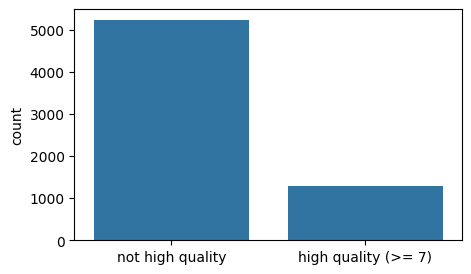

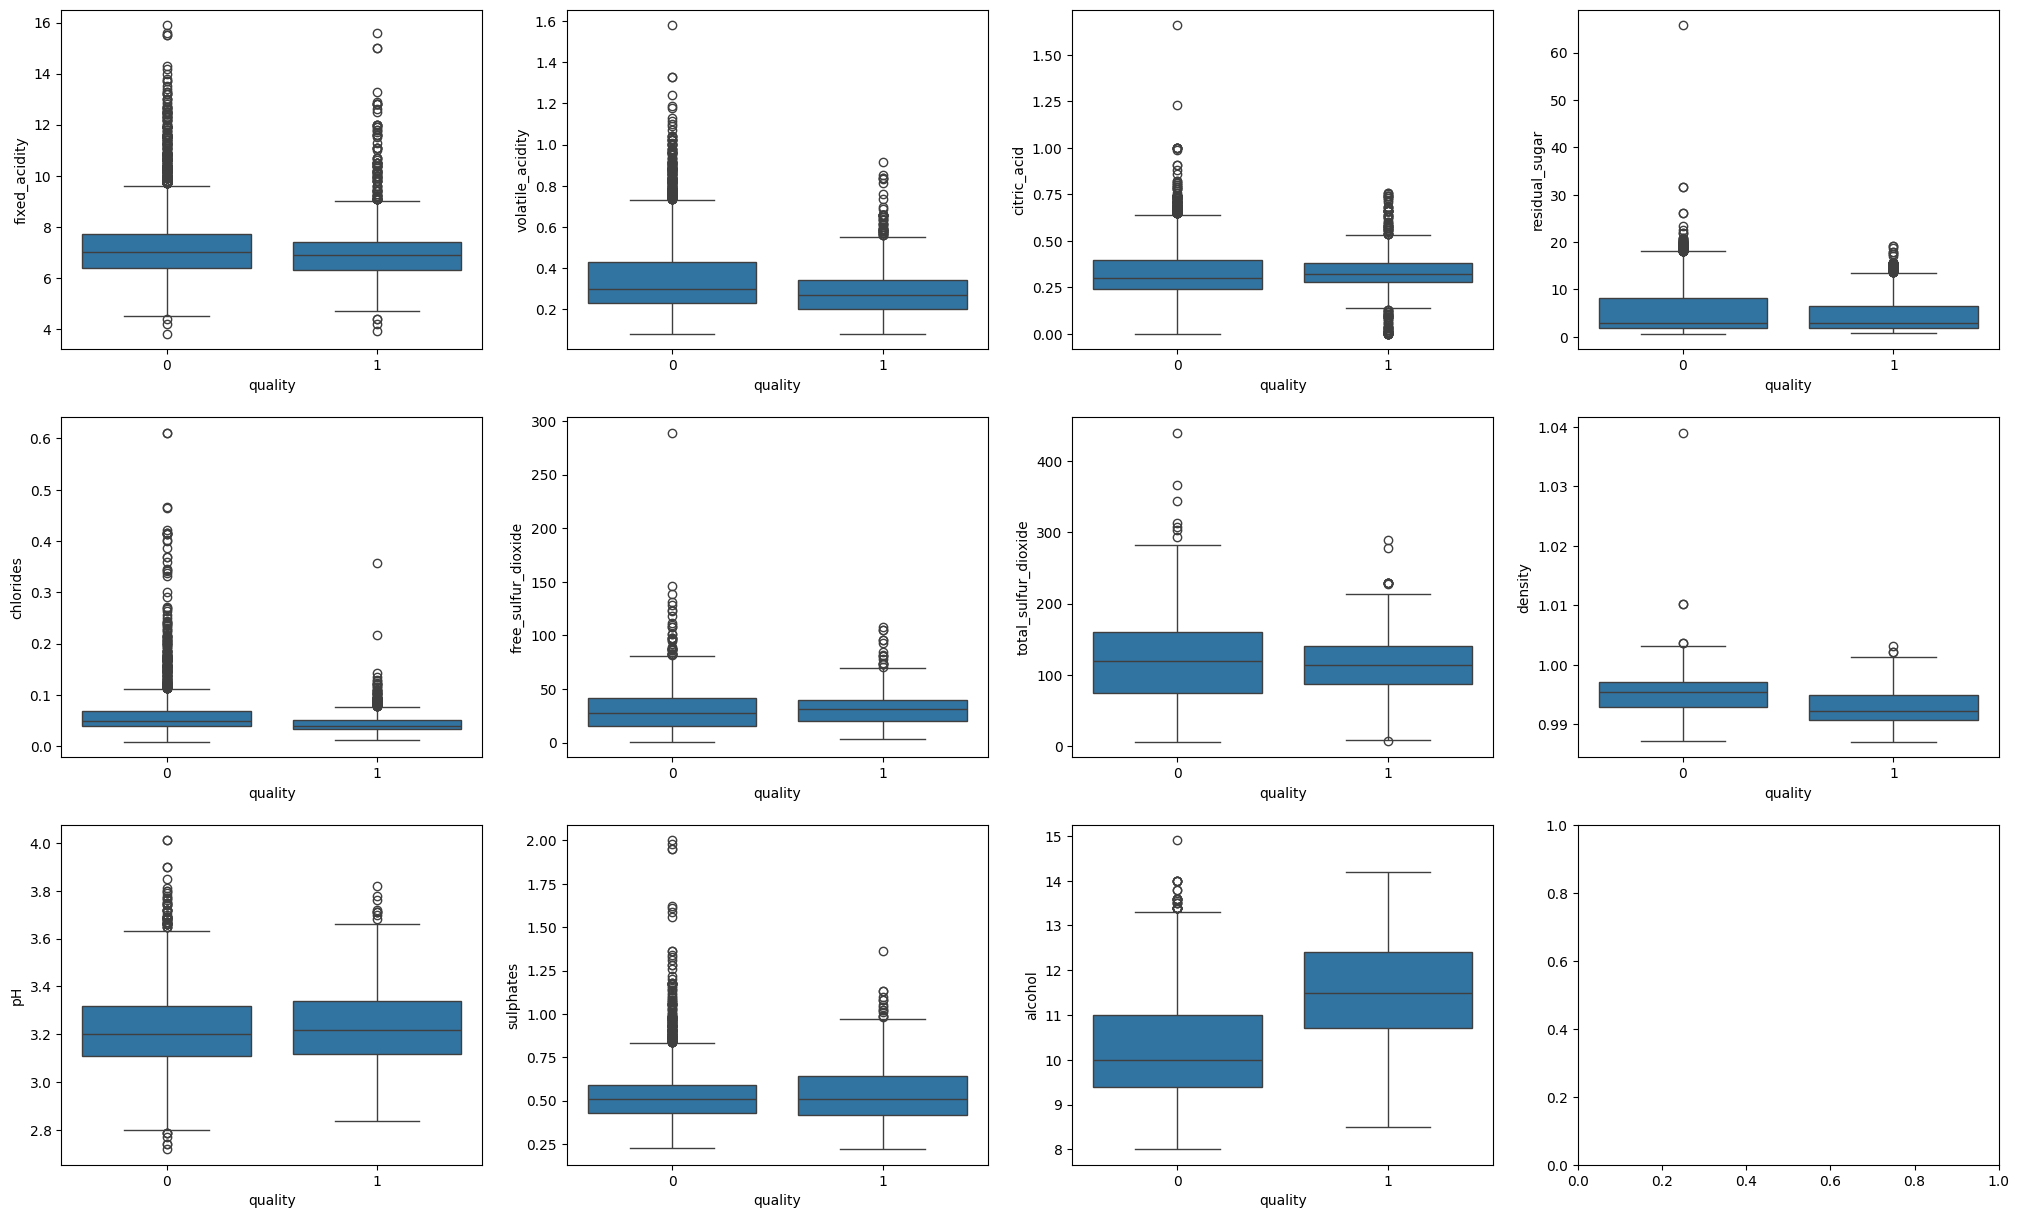

In [3]:
fig, ax = plt.subplots(figsize=(5, 3))
sns.countplot(x=data.quality, ax=ax)
ax.set_xticks([0, 1], ["not high quality", "high quality (>= 7)"])
ax.set_xlabel("")
plt.show()

dims = (3, 4)
f, axes = plt.subplots(dims[0], dims[1], figsize=(25, 15))
axis_i, axis_j = 0, 0
for col in FEATURES:
    if col == "is_red":
        continue  # box plots don't suit indicator variables
    sns.boxplot(x=high_quality, y=data[col], ax=axes[axis_i, axis_j])
    axis_j += 1
    if axis_j == dims[1]:
        axis_i += 1
        axis_j = 0
plt.show()

The same 60 / 20 / 20 split as the original. The roles are now strict: **train** fits models, **validation** compares and selects them, and **test** is touched once, for the final champion in part 6.

Each split is also turned into an **MLflow Dataset**, so every run records exactly which data it was trained and validated on (visible in the run's *Datasets* panel in the UI).

In [4]:
X = data[FEATURES]
y = data.quality
X_train, X_rem, y_train, y_rem = train_test_split(X, y, train_size=0.6, random_state=123)
X_val, X_test, y_val, y_test = train_test_split(X_rem, y_rem, test_size=0.5, random_state=123)
print("train", X_train.shape, "| val", X_val.shape, "| test", X_test.shape)

DATASETS = {
    split: mlflow.data.from_pandas(features.assign(quality=labels), name=f"wine_{split}", targets="quality")
    for split, features, labels in [("train", X_train, y_train), ("validation", X_val, y_val),
                                    ("test", X_test, y_test)]
}

train (3898, 12) | val (1299, 12) | test (1300, 12)


## Shared helpers: one interface and one evaluation for every model

The original logged **test** AUC for the random forest but **validation** AUC for XGBoost, both under the same name `auc`, and then picked "the best run" by sorting on `auc`. That compared different things and used test data for selection. Here:

- **`ProbabilityModel`** wraps every model family (scikit-learn, XGBoost, Keras) behind one pyfunc interface that returns *P(high quality)*. Any registered version can become the champion, and loading or serving code never changes.
- **`log_evaluation()`** logs the same metrics (`val_auc`, `val_accuracy`, `val_f1`, `val_precision`, `val_recall`) and the same plots (ROC curve, precision-recall curve, confusion matrix) for every candidate.
- **`log_candidate()`** logs the wrapped model with its signature and input example, the datasets, and a `candidate=true` tag that the leaderboard filters on.

In [5]:
class ProbabilityModel(mlflow.pyfunc.PythonModel):
    """Common pyfunc interface for every model family: returns P(high quality) per row."""

    def __init__(self, model=None, kind="sklearn"):
        self.kind = kind
        self.model = model if kind != "keras" else None   # Keras models are stored as an artifact

    def load_context(self, context):
        if self.kind == "keras":
            import tensorflow as tf
            self.model = tf.keras.models.load_model(context.artifacts["keras_model"])

    def predict(self, context, model_input, params=None):
        features = model_input[FEATURES].astype("float64")
        if self.kind == "keras":
            return self.model.predict(features.to_numpy("float32"), verbose=0).ravel()
        return self.model.predict_proba(features)[:, 1]


PIP_REQUIREMENTS = [f"mlflow=={mlflow.__version__}", f"scikit-learn=={sklearn.__version__}",
                    f"xgboost=={xgb.__version__}", f"tensorflow=={tf.__version__}",
                    f"pandas=={pd.__version__}", f"numpy=={np.__version__}"]


def log_evaluation(y_true, probabilities, split="val", plots=True, threshold=0.5):
    """Log the same metrics (and optionally the same plots) for any model."""
    labels = (probabilities >= threshold).astype(int)
    metrics = {
        f"{split}_auc": roc_auc_score(y_true, probabilities),
        f"{split}_accuracy": accuracy_score(y_true, labels),
        f"{split}_f1": f1_score(y_true, labels),
        f"{split}_precision": precision_score(y_true, labels, zero_division=0),
        f"{split}_recall": recall_score(y_true, labels),
    }
    mlflow.log_metrics(metrics)
    if plots:
        for name, draw in [("roc_curve", RocCurveDisplay.from_predictions),
                           ("precision_recall_curve", PrecisionRecallDisplay.from_predictions)]:
            fig, ax = plt.subplots(figsize=(5, 4))
            draw(y_true, probabilities, ax=ax)
            ax.set_title(f"{split}: {name.replace('_', ' ')}")
            mlflow.log_figure(fig, f"plots/{split}_{name}.png")
            plt.close(fig)
        fig, ax = plt.subplots(figsize=(4.5, 4))
        ConfusionMatrixDisplay.from_predictions(y_true, labels, ax=ax, colorbar=False)
        ax.set_title(f"{split}: confusion matrix (threshold {threshold})")
        mlflow.log_figure(fig, f"plots/{split}_confusion_matrix.png")
        plt.close(fig)
    return metrics


def log_candidate(wrapper, family, artifacts=None):
    """Log a wrapped model plus datasets and tags; returns validation probabilities."""
    val_probabilities = wrapper.predict(None, X_val) if wrapper.model is not None else None
    mlflow.log_input(DATASETS["train"], context="training")
    mlflow.log_input(DATASETS["validation"], context="validation")
    mlflow.set_tags({"candidate": "true", "model_family": family})
    mlflow.pyfunc.log_model(
        artifact_path="wine_model",
        python_model=wrapper,
        artifacts=artifacts,
        signature=infer_signature(X_val.head(20), np.zeros(20)),
        input_example=X_val.head(3),
        pip_requirements=PIP_REQUIREMENTS,
    )
    return val_probabilities

## 2a. Baseline: random forest

The same untuned random forest as the original (10 trees), now logged with tags, a description, both datasets, validation metrics and plots, and its feature importances as an artifact.

In [6]:
with mlflow.start_run(run_name="random_forest_baseline") as run:
    mlflow.set_tags({"purpose": "baseline",
                     "mlflow.note.content": "Untuned random forest (10 trees), the original lab's baseline."})
    params = {"n_estimators": 10, "random_state": 123}
    mlflow.log_params(params)

    rf = RandomForestClassifier(**params).fit(X_train, y_train)
    val_probabilities = log_candidate(ProbabilityModel(rf, "sklearn"), "random_forest")
    rf_metrics = log_evaluation(y_val, val_probabilities)

    importances = pd.DataFrame({"feature": FEATURES, "importance": rf.feature_importances_}) \
        .sort_values("importance", ascending=False)
    mlflow.log_text(importances.to_csv(index=False), "feature_importance.csv")
    rf_run_id = run.info.run_id

print({k: round(v, 4) for k, v in rf_metrics.items()})
importances

c:\MLOps\Labs\Experiment_Tracking_Labs\Mlflow_Labs\Lab2\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'val_auc': 0.8726, 'val_accuracy': 0.8722, 'val_f1': 0.6327, 'val_precision': 0.6976, 'val_recall': 0.5789}


,feature,importance
10,alcohol,0.160192
7,density,0.117415
1,volatile_acidity,0.093136
4,chlorides,0.086618
3,residual_sugar,0.082544
5,free_sulfur_dioxide,0.080473
8,pH,0.080212
6,total_sulfur_dioxide,0.077798
9,sulphates,0.075780
2,citric_acid,0.071857


## 2b. XGBoost hyperparameter sweep as nested runs, without Spark

The original ran Hyperopt with `SparkTrials`, which needs pyspark and Java and was the main reason the lab was hard to run on Windows. Here Hyperopt's TPE search uses ordinary `Trials`, so it runs anywhere:

- One **parent run**, `xgboost_sweep`, holds the search. Each of the 30 trials is a **nested child run**, shown grouped under the parent in the UI.
- `mlflow.xgboost.autolog()` records each trial's hyperparameters and its **per-iteration** validation AUC curve.
- Each child logs the same `val_*` metrics as every other candidate. The plots are logged only for the best trial, to keep the 30 trials light.
- The parent records the search space, the best parameters, the best child's run id, and a sweep-progress chart.

The search space is also tighter than the original's (`max_depth` 4–12 instead of 4–100), because very deep trees only overfit a dataset this size.

In [7]:
search_space = {
    "max_depth": scope.int(hp.quniform("max_depth", 4, 12, 1)),
    "learning_rate": hp.loguniform("learning_rate", np.log(0.01), np.log(0.3)),
    "min_child_weight": hp.loguniform("min_child_weight", np.log(1), np.log(20)),
    "subsample": hp.uniform("subsample", 0.6, 1.0),
    "colsample_bytree": hp.uniform("colsample_bytree", 0.6, 1.0),
    "reg_lambda": hp.loguniform("reg_lambda", np.log(0.1), np.log(10)),
}
MAX_EVALS = 30


def train_xgboost(params):
    """Hyperopt objective: one nested MLflow run per trial."""
    with mlflow.start_run(run_name="xgboost_trial", nested=True):
        mlflow.set_tag("purpose", "hyperparameter_trial")
        model = xgb.XGBClassifier(n_estimators=1000, early_stopping_rounds=50, eval_metric="auc",
                                  random_state=SEED, **params)
        model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
        val_probabilities = log_candidate(ProbabilityModel(model, "sklearn"), "xgboost")
        metrics = log_evaluation(y_val, val_probabilities, plots=False)
        return {"loss": -metrics["val_auc"], "status": STATUS_OK}


mlflow.xgboost.autolog(log_models=False, log_datasets=False, log_input_examples=False, silent=True)
with mlflow.start_run(run_name="xgboost_sweep") as sweep_run:
    mlflow.set_tags({"purpose": "hyperparameter_sweep",
                     "mlflow.note.content": f"Hyperopt TPE over {MAX_EVALS} XGBoost trials (nested runs)."})
    mlflow.log_params({"max_evals": MAX_EVALS, "algorithm": "tpe",
                       "search_space": "max_depth 4-12, learning_rate 0.01-0.3 (log), min_child_weight 1-20 (log), "
                                       "subsample 0.6-1, colsample_bytree 0.6-1, reg_lambda 0.1-10 (log)"})
    trials = Trials()
    fmin(fn=train_xgboost, space=search_space, algo=tpe.suggest, max_evals=MAX_EVALS,
         trials=trials, rstate=np.random.default_rng(SEED), show_progressbar=False)
mlflow.xgboost.autolog(disable=True)

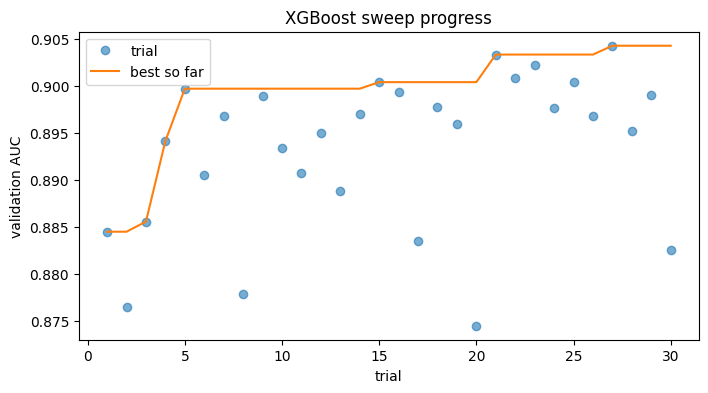

30 trials logged; best val_auc 0.9043 (run 2df3d19c1d9e41aabdf5069aa4baa06d)


In [8]:
# Summarise the sweep on the parent run, using the child runs MLflow just recorded
children = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string=f"tags.mlflow.parentRunId = '{sweep_run.info.run_id}'",
    order_by=["attributes.start_time ASC"],
)
best_child = children.loc[children["metrics.val_auc"].idxmax()]
best_xgb_run_id = best_child.run_id

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(children) + 1), children["metrics.val_auc"], "o", alpha=0.6, label="trial")
ax.plot(range(1, len(children) + 1), children["metrics.val_auc"].cummax(), "-", label="best so far")
ax.set_xlabel("trial")
ax.set_ylabel("validation AUC")
ax.set_title("XGBoost sweep progress")
ax.legend()

with mlflow.start_run(run_id=sweep_run.info.run_id):
    mlflow.log_metrics({"best_val_auc": best_child["metrics.val_auc"], "n_trials": len(children)})
    mlflow.set_tag("best_child_run_id", best_xgb_run_id)
    mlflow.log_params({f"best_{k}": best_child.get(f"params.{k}") for k in search_space})
    mlflow.log_figure(fig, "plots/sweep_progress.png")
plt.show()

# Add the full evaluation plots to the best trial only
best_xgb_model = mlflow.pyfunc.load_model(f"runs:/{best_xgb_run_id}/wine_model")
with mlflow.start_run(run_id=best_xgb_run_id):
    log_evaluation(y_val, best_xgb_model.predict(X_val))

print(f"{len(children)} trials logged; best val_auc {best_child['metrics.val_auc']:.4f} (run {best_xgb_run_id})")

## 2c. TensorFlow/Keras network with autologging

A small feed-forward network, added so the comparison covers a third model family. `mlflow.tensorflow.autolog()` records the optimizer settings and **every epoch's** training and validation loss and AUC. In the UI's *Model metrics* tab these appear as training curves, something the tree models can't show.

The network includes its own `Normalization` layer, so it takes raw feature values like the other models. It's saved in Keras format and attached to the same `ProbabilityModel` wrapper as an artifact.

In [9]:
import tempfile

tf.keras.utils.set_random_seed(SEED)
mlflow.tensorflow.autolog(log_models=False, log_datasets=False, silent=True)

with mlflow.start_run(run_name="keras_mlp") as run:
    mlflow.set_tags({"purpose": "model_family_comparison",
                     "mlflow.note.content": "Feed-forward network (64-32) with input normalization and early stopping."})
    normalizer = tf.keras.layers.Normalization()
    normalizer.adapt(X_train.to_numpy("float32"))
    keras_model = tf.keras.Sequential([
        tf.keras.Input(shape=(len(FEATURES),)),
        normalizer,
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])
    keras_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
                        metrics=[tf.keras.metrics.AUC(name="keras_auc")])
    keras_model.fit(X_train.to_numpy("float32"), y_train.to_numpy(), epochs=100, batch_size=64,
                    validation_data=(X_val.to_numpy("float32"), y_val.to_numpy()), verbose=0,
                    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_keras_auc", mode="max",
                                                                patience=10, restore_best_weights=True)])

    keras_path = os.path.join(tempfile.mkdtemp(), "model.keras")
    keras_model.save(keras_path)
    log_candidate(ProbabilityModel(kind="keras"), "keras_mlp", artifacts={"keras_model": keras_path})
    val_probabilities = keras_model.predict(X_val.to_numpy("float32"), verbose=0).ravel()
    keras_metrics = log_evaluation(y_val, val_probabilities)
    keras_run_id = run.info.run_id

mlflow.tensorflow.autolog(disable=True)
print({k: round(v, 4) for k, v in keras_metrics.items()})

WARNI [tensorflow] From c:\MLOps\Labs\Experiment_Tracking_Labs\Mlflow_Labs\Lab2\.venv\lib\site-packages\keras\src\backend.py:873: The name tf.get_default_graph is deprecated. Please use tf.compat.v1.get_default_graph instead.



WARNI [tensorflow] From c:\MLOps\Labs\Experiment_Tracking_Labs\Mlflow_Labs\Lab2\.venv\lib\site-packages\keras\src\utils\tf_utils.py:492: The name tf.ragged.RaggedTensorValue is deprecated. Please use tf.compat.v1.ragged.RaggedTensorValue instead.



WARNI [tensorflow] Callback method `on_train_batch_end` is slow compared to the batch time (batch time: 0.0013s vs `on_train_batch_end` time: 0.0194s). Check your callbacks.


{'val_auc': 0.8597, 'val_accuracy': 0.8353, 'val_f1': 0.4427, 'val_precision': 0.6204, 'val_recall': 0.3441}


## 3–4. Leaderboard: compare every candidate from code

`mlflow.search_runs` queries the tracking store directly. The filter is scoped to **this experiment** and to runs tagged `candidate = 'true'`: the baseline, every XGBoost trial and the Keras model, but not the sweep's parent run. The original searched across all experiments with no filter. Every row is ranked on the **same validation metric**.

In [10]:
candidates = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string="tags.candidate = 'true' AND attributes.status = 'FINISHED'",
    order_by=["metrics.val_auc DESC"],
)
leaderboard = candidates[["tags.model_family", "tags.mlflow.runName", "metrics.val_auc", "metrics.val_accuracy",
                          "metrics.val_f1", "run_id"]].rename(columns=lambda c: c.split(".")[-1])
print(f"{len(leaderboard)} candidate runs in experiment '{EXPERIMENT_NAME}'")
leaderboard.head(10).round(4)

32 candidate runs in experiment 'wine_quality_tracking'


,model_family,runName,val_auc,val_accuracy,val_f1,run_id
0,xgboost,xgboost_trial,0.9043,0.8868,0.6573,2df3d19c1d9e41aabdf5069aa4baa06d
1,xgboost,xgboost_trial,0.9033,0.8799,0.6372,dcc2395f3b494c809a4b87040d5e63e0
2,xgboost,xgboost_trial,0.9023,0.8822,0.6450,3f233382f5794734817f79c2507b8811
3,xgboost,xgboost_trial,0.9008,0.8768,0.6078,4a081327a89042e0a06e77ef4cbb7689
4,xgboost,xgboost_trial,0.9004,0.8814,0.6402,8a722ed6dc574594afef3c5babe63874
5,xgboost,xgboost_trial,0.9004,0.8822,0.6313,549ae9e6cf584333a9ed70a7e57f6f62
6,xgboost,xgboost_trial,0.8997,0.8776,0.6205,635c9be64a46406f861f0d0605b72686
7,xgboost,xgboost_trial,0.8994,0.8876,0.6756,242409715ded46e0a171ec8aac99851d
8,xgboost,xgboost_trial,0.8990,0.8776,0.6131,205c8e070e2b4b2c9eae66adc9f91d2c
9,xgboost,xgboost_trial,0.8989,0.8730,0.6275,22c220722eff4dd5b12241e2a44356f2


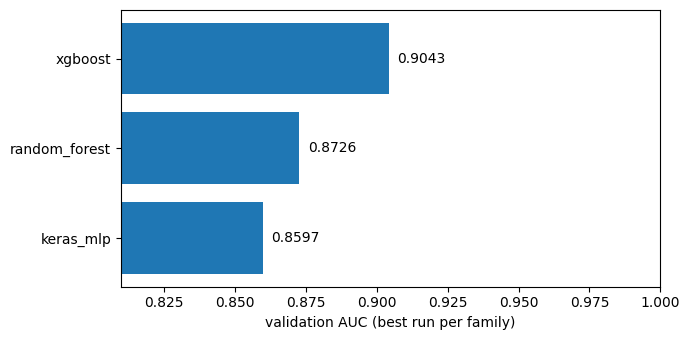

Best candidate: xgboost_trial (xgboost), val_auc 0.9043


,model_family,runName,val_auc,val_accuracy,val_f1,run_id
0,xgboost,xgboost_trial,0.9043,0.8868,0.6573,2df3d19c1d9e41aabdf5069aa4baa06d
1,random_forest,random_forest_baseline,0.8726,0.8722,0.6327,4eaded4273fd47cd8df11d3f50e788d7
2,keras_mlp,keras_mlp,0.8597,0.8353,0.4427,45beac8d4f8947da9a37900467e2f9b9


In [11]:
best_per_family = leaderboard.loc[leaderboard.groupby("model_family")["val_auc"].idxmax()] \
    .sort_values("val_auc", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(best_per_family["model_family"], best_per_family["val_auc"])
ax.set_xlim(best_per_family["val_auc"].min() - 0.05, 1.0)
for i, v in enumerate(best_per_family["val_auc"]):
    ax.text(v + 0.003, i, f"{v:.4f}", va="center")
ax.set_xlabel("validation AUC (best run per family)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

best_candidate = leaderboard.iloc[0]
print(f"Best candidate: {best_candidate['runName']} ({best_candidate['model_family']}), "
      f"val_auc {best_candidate['val_auc']:.4f}")
best_per_family.round(4)

## 5. Model registry: aliases and a promotion gate

The original used registry **stages** (`transition_model_version_stage("Production")`), which MLflow has deprecated in favour of **aliases**. It also promoted the new model unconditionally. Here:

1. If the registry has no `champion` yet, the random forest baseline is registered and becomes the first champion. This plays the role of "the model currently in production".
2. The leaderboard's best candidate is registered as a new version with the alias **`challenger`**.
3. **Promotion gate:** the challenger replaces the champion only if it improves validation AUC by at least `MIN_IMPROVEMENT`. The decision, both scores and the compared version are written as tags on the model version, so the registry keeps an audit trail.

Consumers always load `models:/wine_quality@champion`, so promotion changes which model they get without any code change. Re-running the notebook registers a new challenger and runs the gate again; an identical model is correctly **rejected**, because it doesn't improve on the champion.

In [12]:
MIN_IMPROVEMENT = 0.005


def register_version(run_id, description):
    run = client.get_run(run_id)
    version = mlflow.register_model(f"runs:/{run_id}/wine_model", MODEL_NAME)
    client.update_model_version(MODEL_NAME, version.version, description=description)
    for key, value in {"model_family": run.data.tags["model_family"],
                       "val_auc": f"{run.data.metrics['val_auc']:.4f}",
                       "source_run_name": run.data.tags["mlflow.runName"]}.items():
        client.set_model_version_tag(MODEL_NAME, version.version, key, value)
    return client.get_model_version(MODEL_NAME, version.version)


def get_alias(alias):
    try:
        return client.get_model_version_by_alias(MODEL_NAME, alias)
    except MlflowException:
        return None


# 1) Bootstrap a champion the first time the registry is used
champion = get_alias("champion")
if champion is None:
    champion = register_version(rf_run_id, "Random forest baseline, the first production model.")
    client.set_registered_model_alias(MODEL_NAME, "champion", champion.version)
    client.update_registered_model(MODEL_NAME, description=(
        "Predicts P(high quality) for a wine from its chemistry. Load with models:/wine_quality@champion."))
    print(f"No champion yet: registered the baseline as version {champion.version} and made it champion")

# 2) Register the best candidate as challenger
challenger = register_version(best_candidate["run_id"],
                              f"Best candidate from the leaderboard ({best_candidate['model_family']}).")
client.set_registered_model_alias(MODEL_NAME, "challenger", challenger.version)
print(f"Registered challenger: version {challenger.version} ({challenger.tags['model_family']}, "
      f"val_auc {challenger.tags['val_auc']})")

No champion yet: registered the baseline as version 1 and made it champion
Registered challenger: version 2 (xgboost, val_auc 0.9043)


Successfully registered model 'wine_quality'.
Created version '1' of model 'wine_quality'.
Registered model 'wine_quality' already exists. Creating a new version of this model...
Created version '2' of model 'wine_quality'.


In [13]:
# 3) Promotion gate
champion = get_alias("champion")
champion_auc, challenger_auc = float(champion.tags["val_auc"]), float(challenger.tags["val_auc"])
improvement = challenger_auc - champion_auc
promote = improvement >= MIN_IMPROVEMENT

decision_tags = {"gate_compared_with_version": champion.version, "gate_champion_val_auc": f"{champion_auc:.4f}",
                 "gate_val_auc_improvement": f"{improvement:+.4f}", "gate_min_improvement": str(MIN_IMPROVEMENT),
                 "gate_decision": "promoted" if promote else "rejected"}
for key, value in decision_tags.items():
    client.set_model_version_tag(MODEL_NAME, challenger.version, key, value)

if promote:
    client.set_registered_model_alias(MODEL_NAME, "champion", challenger.version)   # moves the alias
    client.delete_registered_model_alias(MODEL_NAME, "challenger")
    client.set_model_version_tag(MODEL_NAME, champion.version, "status", "retired")
    client.set_model_version_tag(MODEL_NAME, challenger.version, "status", "champion")
    print(f"PROMOTED: version {challenger.version} ({challenger_auc:.4f}) replaces version "
          f"{champion.version} ({champion_auc:.4f}), improvement {improvement:+.4f}")
else:
    client.set_model_version_tag(MODEL_NAME, challenger.version, "status", "rejected")
    print(f"REJECTED: version {challenger.version} ({challenger_auc:.4f}) does not beat champion version "
          f"{champion.version} ({champion_auc:.4f}) by {MIN_IMPROVEMENT}; champion unchanged")

versions = client.search_model_versions(f"name = '{MODEL_NAME}'")
registry = pd.DataFrame([{"version": int(v.version), "aliases": ", ".join(v.aliases) or "-",
                          "family": v.tags.get("model_family"), "val_auc": v.tags.get("val_auc"),
                          "status": v.tags.get("status", "-"), "gate_decision": v.tags.get("gate_decision", "-")}
                         for v in versions]).sort_values("version")
registry

PROMOTED: version 2 (0.9043) replaces version 1 (0.8726), improvement +0.0317


,version,aliases,family,val_auc,status,gate_decision
1,1,-,random_forest,0.8726,retired,-
0,2,-,xgboost,0.9043,champion,promoted


## 6. Use the champion

### Final test evaluation (the only time the test set is used)

The champion is loaded **by alias** and scored once on the held-out test set. The result is logged as its own run and written back to the model version as a tag.

In [14]:
champion = get_alias("champion")
CHAMPION_URI = f"models:/{MODEL_NAME}@champion"
champion_model = mlflow.pyfunc.load_model(CHAMPION_URI)

with mlflow.start_run(run_name="champion_test_evaluation"):
    mlflow.set_tags({"purpose": "final_test_evaluation", "model_version": champion.version,
                     "model_family": champion.tags["model_family"]})
    mlflow.log_param("model_uri", CHAMPION_URI)
    mlflow.log_input(DATASETS["test"], context="test")
    test_metrics = log_evaluation(y_test, champion_model.predict(X_test), split="test")

client.set_model_version_tag(MODEL_NAME, champion.version, "test_auc", f"{test_metrics['test_auc']:.4f}")
print(f"Champion = version {champion.version} ({champion.tags['model_family']})")
print({k: round(v, 4) for k, v in test_metrics.items()})

Champion = version 2 (xgboost)
{'test_auc': 0.9061, 'test_accuracy': 0.8823, 'test_f1': 0.6515, 'test_precision': 0.7814, 'test_recall': 0.5586}


### Batch inference without Spark

The original created a Spark UDF for batch scoring, but its data-loading line was commented out, so batch inference never actually ran (and it needed pyspark and Java). Here the champion scores a batch of incoming wines with pandas. The predictions are logged as an artifact, together with the input dataset and the exact model version used.

In [15]:
incoming_batch = X_test.sample(200, random_state=SEED)   # stands in for new, unlabeled wines

with mlflow.start_run(run_name="batch_inference"):
    mlflow.set_tags({"purpose": "batch_inference", "model_version": champion.version})
    mlflow.log_param("model_uri", CHAMPION_URI)
    mlflow.log_input(mlflow.data.from_pandas(incoming_batch, name="incoming_batch"), context="inference")

    probabilities = champion_model.predict(incoming_batch)
    predictions = incoming_batch.assign(p_high_quality=probabilities,
                                        predicted_high_quality=(probabilities >= 0.5).astype(int),
                                        model_version=champion.version)
    mlflow.log_text(predictions.to_csv(index=False), "batch_predictions.csv")
    mlflow.log_metrics({"batch_size": len(predictions),
                        "predicted_high_quality_share": float(predictions.predicted_high_quality.mean())})

print(f"Scored {len(predictions)} wines with version {champion.version}; "
      f"{predictions.predicted_high_quality.mean():.1%} predicted high quality")
predictions[["alcohol", "density", "volatile_acidity", "p_high_quality", "predicted_high_quality"]].head()

Scored 200 wines with version 2; 14.5% predicted high quality


,alcohol,density,volatile_acidity,p_high_quality,predicted_high_quality
5610,12.8,0.98944,0.260,0.900189,1
3522,10.4,0.99230,0.370,0.007765,0
658,9.6,0.99730,0.520,0.004393,0
3105,11.0,0.99540,0.200,0.336956,0
257,9.2,0.99680,0.695,0.000510,0


### Real-time serving by alias

Serve the champion as a REST API from a **second terminal** (in this folder, with the virtual environment active). PowerShell:

```
$env:MLFLOW_TRACKING_URI = "sqlite:///mlruns/mlflow.db"
mlflow models serve -m "models:/wine_quality@champion" --env-manager local --port 5001
```

macOS/Linux: `MLFLOW_TRACKING_URI=sqlite:///mlruns/mlflow.db mlflow models serve -m "models:/wine_quality@champion" --env-manager local --port 5001`

Once it prints that it's listening, run the next cell. It sends 5 wines to the server and checks that the **served predictions match the champion loaded in the notebook**. Because the server resolves the alias at startup, promoting a new champion only needs a server restart, not a code change.

In [17]:
import requests

sample = incoming_batch.head(5)
try:
    response = requests.post("http://127.0.0.1:5001/invocations",
                             json={"dataframe_split": sample.to_dict(orient="split")}, timeout=30)
    response.raise_for_status()
    served = np.array(response.json()["predictions"], dtype=float)
    local = champion_model.predict(sample)
    print("Served by REST API:", np.round(served, 4))
    print("Loaded in notebook:", np.round(local, 4))
    print("Match:", bool(np.allclose(served, local, atol=1e-6)))
except requests.exceptions.ConnectionError:
    print("The model server isn't running. Start it with the command above, then re-run this cell.")

Served by REST API: [9.002e-01 7.800e-03 4.400e-03 3.370e-01 5.000e-04]
Loaded in notebook: [9.002e-01 7.800e-03 4.400e-03 3.370e-01 5.000e-04]
Match: True


## Wrap up

This notebook tracked a full model-development cycle in MLflow:

- **Experiments are organized:** a named experiment, tagged runs with descriptions, datasets attached to every run, and nested runs for the sweep.
- **Every candidate is evaluated the same way** on validation data, so the leaderboard compares like with like. The test set is used once.
- **Three model families** (random forest, XGBoost, Keras) sit behind one pyfunc interface, so the registry can promote any of them.
- **The registry uses aliases and a promotion gate** that records its decision on the model version.
- **Consumers load and serve by alias,** so promoting a model changes what they get without changing their code.

Open the MLflow UI (http://127.0.0.1:5000) to explore the runs, charts, comparisons and the registry.